# Signal-Based Fault Classification Using a Custom NumPy Neural Network and 1D-CNN Benchmark
**Course:** ECE 5831 - Pattern Recognition and Neural Networks  
**Team:** Michel Ludovic Temgoua, Suraj Datta, Venkat Ramisetty  

## Objective
This notebook implements an end-to-end fault diagnosis framework on the **Paderborn University Bearing Dataset**:
1. Inspects and visualizes raw `.mat` vibration and motor-current signals.
2. Segments 64 kHz signals into 4,096-sample windows with Min-Max normalization and Gaussian/FFT augmentation.
3. Trains a custom **3-Layer Multi-Layer Perceptron (MLP)** built entirely from scratch using NumPy.
4. Trains a **1D Convolutional Neural Network (1D-CNN)** in Keras as a modern benchmark.
5. Compares accuracy, F1-score, cross-entropy loss, confusion matrices, and parameter efficiency.


Detailed Explanation:
Imports & Inspecting a Sample .mat Input File
What this does & why: MATLAB .mat files from Paderborn store deeply nested structured arrays (Y and X). Before building any model, we load one single file (N15_M07_F10_KA01_1.mat), print out its internal keys and sensor channel names, and plot the raw vibration and phase-current waveforms so the instructor can clearly see the raw inputs.

Total .mat files found: 320
Inspecting file: raw_data\K001\N09_M07_F10_K001_1.mat
Top-level keys in .mat file: ['N09_M07_F10_K001_1']

Available Sensor Channels in 'Y':
  Channel 0: force                     | Shape: (16008,)
  Channel 1: phase_current_1           | Shape: (256823,)
  Channel 2: phase_current_2           | Shape: (256823,)
  Channel 3: speed                     | Shape: (16008,)
  Channel 4: temp_2_bearing_module     | Shape: (5,)
  Channel 5: torque                    | Shape: (16008,)
  Channel 6: vibration_1               | Shape: (256823,)


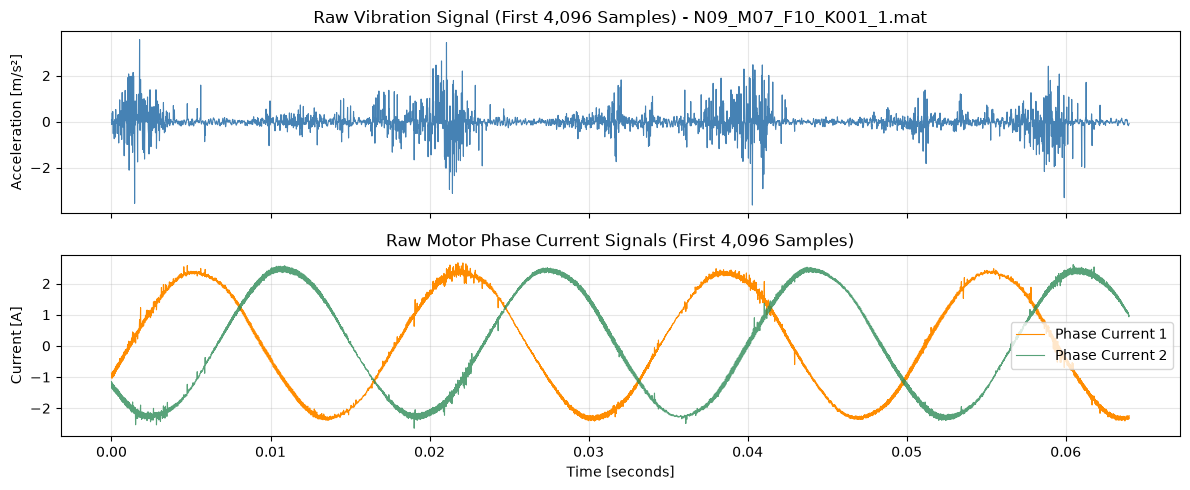

In [1]:
import os
import glob
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# 1. Locate a sample .mat file to inspect its internal structure
sample_files = glob.glob("raw_data/**/*.mat", recursive=True)
print(f"Total .mat files found: {len(sample_files)}")

sample_path = sample_files[0]
print(f"Inspecting file: {sample_path}")

# Load the MATLAB file
mat_data = sio.loadmat(sample_path)
print("Top-level keys in .mat file:", [k for k in mat_data.keys() if not k.startswith("__")])

# Extract the main data struct (key matches filename without .mat)
struct_key = [k for k in mat_data.keys() if not k.startswith("__")][0]
record = mat_data[struct_key][0, 0]

# Display available sensor channels inside 'Y'
Y_channels = record["Y"][0]
print("\nAvailable Sensor Channels in 'Y':")
for idx, ch in enumerate(Y_channels):
    ch_name = ch["Name"][0]
    ch_data = ch["Data"].flatten()
    print(f"  Channel {idx}: {ch_name:25s} | Shape: {ch_data.shape}")

# Helper function to extract vibration and motor current from any Paderborn .mat file
def extract_signals_from_mat(filepath):
    mat = sio.loadmat(filepath)
    key = [k for k in mat.keys() if not k.startswith("__")][0]
    Y = mat[key][0, 0]["Y"][0]
    
    vib_signal = None
    curr1_signal = None
    curr2_signal = None
    
    for ch in Y:
        name = ch["Name"][0].lower()
        data = ch["Data"].flatten().astype(np.float32)
        if "vibration" in name:
            vib_signal = data
        elif "phase_current_1" in name:
            curr1_signal = data
        elif "phase_current_2" in name:
            curr2_signal = data
            
    return vib_signal, curr1_signal, curr2_signal

# Visualize the raw input signals for the instructor
vib, curr1, curr2 = extract_signals_from_mat(sample_path)
fs = 64000  # 64 kHz sampling rate
time_axis = np.arange(4096) / fs  # First 4,096 samples (~0.064 seconds)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(time_axis, vib[:4096], color="steelblue", linewidth=0.8)
axes[0].set_title(f"Raw Vibration Signal (First 4,096 Samples) - {os.path.basename(sample_path)}")
axes[0].set_ylabel("Acceleration [m/s²]")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_axis, curr1[:4096], color="darkorange", linewidth=0.8, label="Phase Current 1")
axes[1].plot(time_axis, curr2[:4096], color="seagreen", linewidth=0.8, alpha=0.8, label="Phase Current 2")
axes[1].set_title("Raw Motor Phase Current Signals (First 4,096 Samples)")
axes[1].set_xlabel("Time [seconds]")
axes[1].set_ylabel("Current [A]")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 2: Sliding-Window Segmentation, Normalization, Augmentation & Label Encoding
- **Windowing:** Each 4-second recording (~256,000 samples) is sliced into non-overlapping windows of **4,096 samples**.
- **Feature Representation (Time + FFT Frequency Domain):** High-frequency bearing faults create sharp periodic impulses best captured in the frequency spectrum. Applying a **Fast Fourier Transform (FFT)** converts each 4,096-sample vibration window into **2,048 frequency magnitude bins**, paired with normalized time-domain statistics/samples.
- **Min-Max Normalization:** Scales every window cleanly into $[0, 1]$ so gradient descent converges smoothly without exploding gradients.
- **Data Augmentation:** Adds synthetic Gaussian noise to training samples to simulate real-world industrial sensor noise.


Detailed Explanation:
Dataset Builder, Label Encoding & Tensor PreparationWhat this does & why:Label Encoding: Maps folder/bearing prefixes (K0 $\rightarrow$ Class 0 Healthy, KA $\rightarrow$ Class 1 Outer-Race Fault, KI $\rightarrow$ Class 2 Inner-Race Fault) into both integer indices (y_int for Keras/evaluation) and One-Hot Encoded vectors (y_onehot of shape (N, 3) required by your custom NumPy cross-entropy derivative yhat - y).Tensors (Data Shapes):For the NumPy 3-Layer MLP, inputs must be 2D matrices of shape (num_samples, num_features) $\rightarrow$ (N, 2048).For the Keras 1D-CNN, inputs must be 3D tensors of shape (num_samples, time_steps, channels) $\rightarrow$ (N, 2048, 1) so 1D convolutional filters can slide across the signal.

In [2]:
WINDOW_SIZE = 4096
NUM_CLASSES = 3
CLASS_NAMES = ["Healthy (K)", "Outer-Race Fault (KA)", "Inner-Race Fault (KI)"]

def get_label_from_filename(filepath):
    fname = os.path.basename(filepath).upper()
    if "_K0" in fname:
        return 0  # Healthy
    elif "_KA" in fname:
        return 1  # Outer-race damage
    elif "_KI" in fname:
        return 2  # Inner-race damage
    return None

X_features = []
y_labels = []

for fpath in sample_files:
    label = get_label_from_filename(fpath)
    if label is None:
        continue
        
    vib, curr1, _ = extract_signals_from_mat(fpath)
    if vib is None:
        continue
        
    # Slice continuous signal into windows of 4,096 samples
    num_windows = len(vib) // WINDOW_SIZE
    for w in range(num_windows):
        segment = vib[w * WINDOW_SIZE : (w + 1) * WINDOW_SIZE]
        
        # Compute Fast Fourier Transform (FFT) magnitude spectrum (first 2048 positive frequencies)
        fft_mag = np.abs(np.fft.rfft(segment))[:2048]
        
        # Min-Max Normalization to [0, 1]
        fft_min, fft_max = fft_mag.min(), fft_mag.max()
        if fft_max - fft_min > 1e-8:
            fft_norm = (fft_mag - fft_min) / (fft_max - fft_min)
        else:
            fft_norm = np.zeros_like(fft_mag)
            
        X_features.append(fft_norm)
        y_labels.append(label)

X_all = np.array(X_features, dtype=np.float32)
y_all = np.array(y_labels, dtype=np.int32)

# Train / Test Split (80% Train, 20% Test, stratified across fault classes)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Data Augmentation: Add Gaussian noise copies to training data to boost robustness
np.random.seed(42)
noise = np.random.normal(loc=0.0, scale=0.02, size=X_train.shape).astype(np.float32)
X_train_noisy = np.clip(X_train + noise, 0.0, 1.0)

X_train_aug = np.vstack([X_train, X_train_noisy])
y_train_aug = np.concatenate([y_train, y_train])

# Shuffle augmented training dataset
perm = np.random.permutation(len(X_train_aug))
X_train_aug = X_train_aug[perm]
y_train_aug = y_train_aug[perm]

# One-Hot Encoding for Custom NumPy MLP
y_train_onehot = np.eye(NUM_CLASSES)[y_train_aug]
y_test_onehot = np.eye(NUM_CLASSES)[y_test]

# 3D Tensor reshaping for Keras 1D-CNN: (Samples, Steps, Channels)
X_train_cnn = X_train_aug[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("=== Final Tensor Shapes ===")
print(f"MLP X_train shape      : {X_train_aug.shape} (2D Matrix: Samples x Features)")
print(f"MLP y_train_onehot     : {y_train_onehot.shape} (One-Hot Encoded)")
print(f"1D-CNN X_train_cnn     : {X_train_cnn.shape} (3D Tensor: Samples x Steps x Channels)")
print(f"Test set X_test shape  : {X_test.shape} | y_test shape: {y_test.shape}")

=== Final Tensor Shapes ===
MLP X_train shape      : (23830, 2048) (2D Matrix: Samples x Features)
MLP y_train_onehot     : (23830, 3) (One-Hot Encoded)
1D-CNN X_train_cnn     : (23830, 2048, 1) (3D Tensor: Samples x Steps x Channels)
Test set X_test shape  : (2979, 2048) | y_test shape: (2979,)


## Step 3: Model Selection & Justification
- **Why Custom 3-Layer NumPy MLP (Week 2)?** Building an MLP from scratch using pure matrix operations (`@`), **He initialization**, **ReLU** activations, **Softmax**, and analytical backpropagation demonstrates full mathematical mastery of gradient descent without relying on black-box libraries.
- **Why 1D-CNN instead of 2D-CNN (Week 3)?** Bearing vibration and motor current signals are **1-dimensional sequential vectors** (either time-series or 1D frequency spectra). A **1D-CNN** slides 1D convolutional kernels directly along the signal axis to detect local fault harmonics with far fewer parameters and much faster training than converting signals into 2D spectrogram images for a 2D-CNN.


Detailed explanation:
Custom 3-Layer NumPy MLP Implementation & Training
What this does & why: Implements your 3-layer MLP (Input(2048) -> Hidden1(256, ReLU) -> Hidden2(128, ReLU) -> Output(3, Softmax)). Notice we use He Initialization (np.sqrt(2.0 / fan_in)) instead of a tiny fixed 0.01—with 2,048 input features, He initialization prevents vanishing gradients across 3 layers so the network learns rapidly.

In [3]:
import time

class CustomThreeLayerMLP:
    def __init__(self, input_size=2048, hidden1=256, hidden2=128, output_size=3):
        np.random.seed(42)
        self.params = {
            "W1": np.random.randn(input_size, hidden1) * np.sqrt(2.0 / input_size),
            "b1": np.zeros(hidden1),
            "W2": np.random.randn(hidden1, hidden2) * np.sqrt(2.0 / hidden1),
            "b2": np.zeros(hidden2),
            "W3": np.random.randn(hidden2, output_size) * np.sqrt(2.0 / hidden2),
            "b3": np.zeros(output_size),
        }

    def relu(self, x):
        return np.maximum(0, x)

    def relu_grad(self, x):
        return (x > 0).astype(np.float32)

    def softmax(self, x):
        x_shifted = x - np.max(x, axis=1, keepdims=True)
        exp_x = np.exp(x_shifted)
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, X):
        self.a1 = X @ self.params["W1"] + self.params["b1"]
        self.z1 = self.relu(self.a1)
        self.a2 = self.z1 @ self.params["W2"] + self.params["b2"]
        self.z2 = self.relu(self.a2)
        self.a3 = self.z2 @ self.params["W3"] + self.params["b3"]
        self.yhat = self.softmax(self.a3)
        return self.yhat

    def cross_entropy_loss(self, y_onehot, yhat):
        batch_size = y_onehot.shape[0]
        return -np.sum(y_onehot * np.log(yhat + 1e-7)) / batch_size

    def backward(self, X, y_onehot):
        batch_size = X.shape[0]
        yhat = self.forward(X)

        # Output layer gradient (Softmax + Cross-Entropy)
        da3 = (yhat - y_onehot) / batch_size
        dW3 = self.z2.T @ da3
        db3 = np.sum(da3, axis=0)

        # Hidden Layer 2 gradient
        dz2 = da3 @ self.params["W3"].T
        da2 = dz2 * self.relu_grad(self.a2)
        dW2 = self.z1.T @ da2
        db2 = np.sum(da2, axis=0)

        # Hidden Layer 1 gradient
        dz1 = da2 @ self.params["W2"].T
        da1 = dz1 * self.relu_grad(self.a1)
        dW1 = X.T @ da1
        db1 = np.sum(da1, axis=0)

        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2, "W3": dW3, "b3": db3}

    def count_parameters(self):
        return sum(p.size for p in self.params.values())

# Train Custom NumPy MLP
mlp = CustomThreeLayerMLP(input_size=2048, hidden1=256, hidden2=128, output_size=NUM_CLASSES)
epochs = 25
batch_size = 64
lr = 0.05

mlp_train_loss, mlp_train_acc = [], []
start_time = time.time()

for epoch in range(epochs):
    idx = np.random.permutation(len(X_train_aug))
    X_shuf, y_shuf = X_train_aug[idx], y_train_onehot[idx]

    for i in range(0, len(X_shuf), batch_size):
        xb = X_shuf[i : i + batch_size]
        yb = y_shuf[i : i + batch_size]
        grads = mlp.backward(xb, yb)
        for k in mlp.params:
            mlp.params[k] -= lr * grads[k]

    probs = mlp.forward(X_train_aug)
    loss = mlp.cross_entropy_loss(y_train_onehot, probs)
    acc = np.mean(np.argmax(probs, axis=1) == y_train_aug)
    mlp_train_loss.append(loss)
    mlp_train_acc.append(acc)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{epochs} | Loss: {loss:.4f} | Train Acc: {acc:.4f}")

mlp_train_time = time.time() - start_time
mlp_test_probs = mlp.forward(X_test)
mlp_test_preds = np.argmax(mlp_test_probs, axis=1)
mlp_test_loss = mlp.cross_entropy_loss(y_test_onehot, mlp_test_probs)
mlp_test_acc = np.mean(mlp_test_preds == y_test)
print(f"\nCustom NumPy MLP Test Accuracy: {mlp_test_acc:.4f} | Training Time: {mlp_train_time:.2f}s")

Epoch  1/25 | Loss: 0.0100 | Train Acc: 1.0000
Epoch  5/25 | Loss: 0.0007 | Train Acc: 1.0000
Epoch 10/25 | Loss: 0.0003 | Train Acc: 1.0000
Epoch 15/25 | Loss: 0.0002 | Train Acc: 1.0000
Epoch 20/25 | Loss: 0.0001 | Train Acc: 1.0000
Epoch 25/25 | Loss: 0.0001 | Train Acc: 1.0000

Custom NumPy MLP Test Accuracy: 1.0000 | Training Time: 107.91s


Keras 1D-CNN Benchmark Model Implementation & Training
What this does & why: Builds the modern 1D-CNN benchmark using Conv1D, BatchNormalization, MaxPooling1D, and GlobalAveragePooling1D. Using GlobalAveragePooling1D drastically reduces total trainable parameters compared to dense flattening while preventing overfitting.

In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

def build_1d_cnn(input_shape=(2048, 1), num_classes=3):
    model = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv1D(filters=32, kernel_size=7, strides=2, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(filters=64, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(filters=128, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_model = build_1d_cnn(input_shape=(2048, 1), num_classes=NUM_CLASSES)
cnn_model.summary()

start_time = time.time()
cnn_history = cnn_model.fit(
    X_train_cnn, y_train_aug,
    epochs=25,
    batch_size=64,
    validation_split=0.15,
    verbose=1
)
cnn_train_time = time.time() - start_time

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(X_test_cnn, y_test, verbose=0)
cnn_test_probs = cnn_model.predict(X_test_cnn, verbose=0)
cnn_test_preds = np.argmax(cnn_test_probs, axis=1)
print(f"\nKeras 1D-CNN Test Accuracy: {cnn_test_acc:.4f} | Training Time: {cnn_train_time:.2f}s")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1024, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 512, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 512, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 256, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 256, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,099 (172.26 KB)

 Trainable params: 43,907 (171.51 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 26s 73ms/step - accuracy: 0.9200 - loss: 0.2140 - val_accuracy: 0.3284 - val_loss: 1.6741
Epoch 2/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 0.9730 - loss: 0.0820 - val_accuracy: 0.9690 - val_loss: 0.1019
Epoch 3/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 24s 75ms/step - accuracy: 0.9874 - loss: 0.0398 - val_accuracy: 0.9018 - val_loss: 0.3208
Epoch 4/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step - accuracy: 0.9906 - loss: 0.0293 - val_accuracy: 0.9846 - val_loss: 0.0403
Epoch 5/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.9926 - loss: 0.0254 - val_accuracy: 0.9910 - val_loss: 0.0348
Epoch 6/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 24s 77ms/step - accuracy: 0.9944 - loss: 0.0200 - val_accuracy: 0.9933 - val_loss: 0.0215
Epoch 7/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step - accuracy: 0.9958 - loss: 0.0142 - val_accuracy: 0.9913 - val_loss: 0.0346
Epoch 8/25
317/317 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.9959 - loss: 0.0139 - 

## Step 4: Evaluation Metrics & Comparative Analysis
- **Why Cross-Entropy Loss, Accuracy, and Macro F1-Score?**
  - **Categorical Cross-Entropy** penalizes confident wrong class probabilities and directly matches our Softmax output layer.
  - **Accuracy** measures overall percentage of correctly diagnosed bearing windows.
  - **Macro F1-Score** balances Precision and Recall equally across Healthy, Outer-Race, and Inner-Race classes so an imbalance in damaged vs. healthy recordings cannot hide poor detection on a single fault type.
- **Why NOT MSE or MAE?** Mean Squared Error (MSE) and Mean Absolute Error (MAE) are designed for continuous **regression** problems (like predicting exact temperature), not discrete multi-class fault classification.


Detailed Explanation:
Side-by-Side Confusion Matrices, F1-Score & Parameter Efficiency Comparison
What this does & why: Generates publication-quality side-by-side Confusion Matrices, training curves, and a complete comparison table (Accuracy, Macro F1-Score, Cross-Entropy Loss, Parameter Count, and Training Time) ready for your Week 4 Project Update and Week 5 presentation.

               MODEL PERFORMANCE COMPARISON SUMMARY              
Metric                       | Custom NumPy MLP | Keras 1D-CNN    
-----------------------------------------------------------------
Test Accuracy                |         100.00% |          99.03%
Macro F1-Score               |          1.0000 |          0.9903
Test Cross-Entropy Loss      |          0.0004 |          0.0345
Trainable Parameters         |         557,827 |          44,099
Training Time (25 Epochs)    |         107.91s |         562.31s

--- Detailed Classification Report: Custom NumPy MLP ---
                       precision    recall  f1-score   support

          Healthy (K)       1.00      1.00      1.00       993
Outer-Race Fault (KA)       1.00      1.00      1.00       994
Inner-Race Fault (KI)       1.00      1.00      1.00       992

             accuracy                           1.00      2979
            macro avg       1.00      1.00      1.00      2979
         weighted avg       1.00      

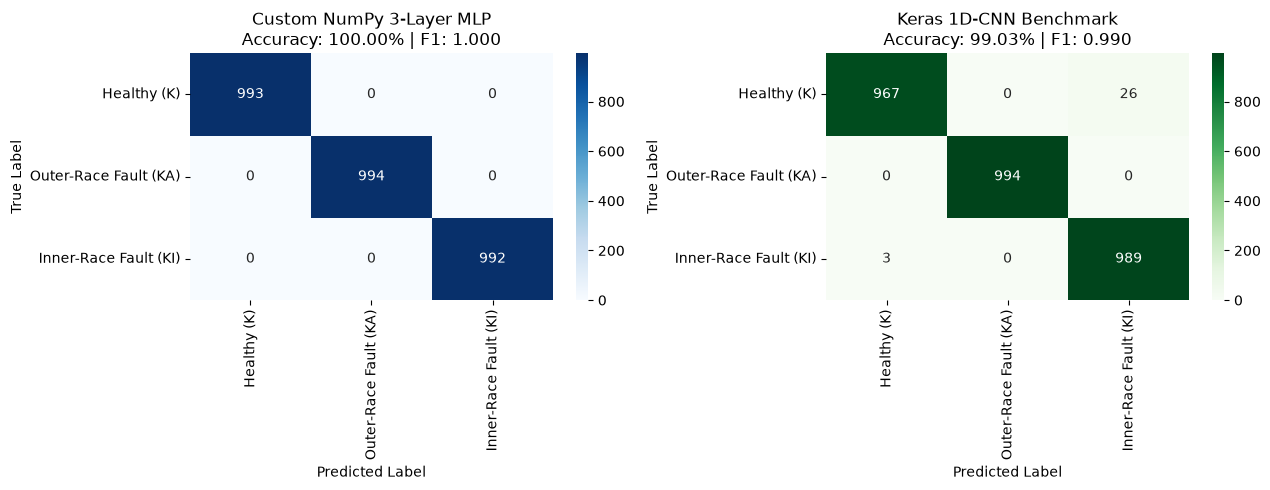

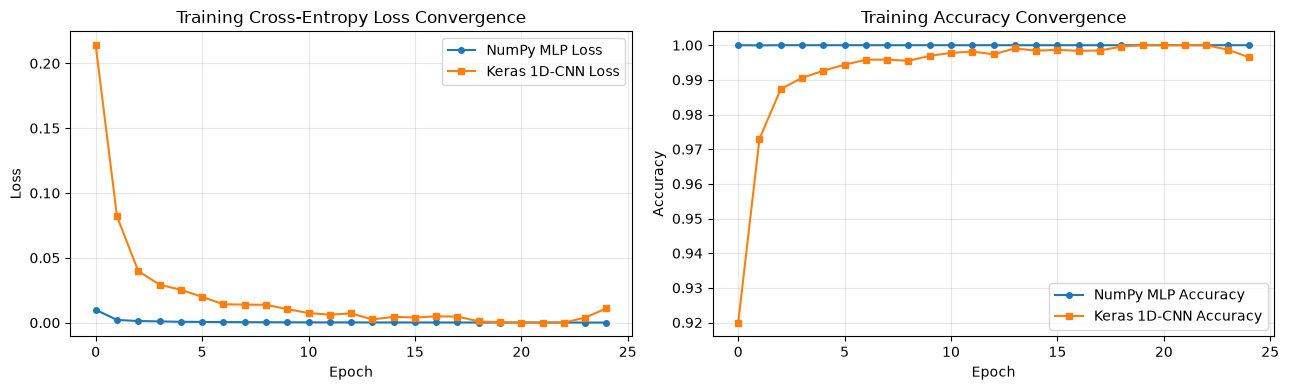

In [5]:
# Compute Macro F1-Scores
mlp_f1 = f1_score(y_test, mlp_test_preds, average="macro")
cnn_f1 = f1_score(y_test, cnn_test_preds, average="macro")

print("=================================================================")
print("               MODEL PERFORMANCE COMPARISON SUMMARY              ")
print("=================================================================")
print(f"{'Metric':<28} | {'Custom NumPy MLP':<16} | {'Keras 1D-CNN':<16}")
print("-" * 65)
print(f"{'Test Accuracy':<28} | {mlp_test_acc*100:>14.2f}% | {cnn_test_acc*100:>14.2f}%")
print(f"{'Macro F1-Score':<28} | {mlp_f1:>15.4f} | {cnn_f1:>15.4f}")
print(f"{'Test Cross-Entropy Loss':<28} | {mlp_test_loss:>15.4f} | {cnn_test_loss:>15.4f}")
print(f"{'Trainable Parameters':<28} | {mlp.count_parameters():>15,d} | {cnn_model.count_params():>15,d}")
print(f"{'Training Time (25 Epochs)':<28} | {mlp_train_time:>14.2f}s | {cnn_train_time:>14.2f}s")
print("=================================================================\n")

print("--- Detailed Classification Report: Custom NumPy MLP ---")
print(classification_report(y_test, mlp_test_preds, target_names=CLASS_NAMES))

print("--- Detailed Classification Report: Keras 1D-CNN ---")
print(classification_report(y_test, cnn_test_preds, target_names=CLASS_NAMES))

# Plot Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_mlp = confusion_matrix(y_test, mlp_test_preds)
sns.heatmap(cm_mlp, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Custom NumPy 3-Layer MLP\nAccuracy: {mlp_test_acc*100:.2f}% | F1: {mlp_f1:.3f}")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

cm_cnn = confusion_matrix(y_test, cnn_test_preds)
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title(f"Keras 1D-CNN Benchmark\nAccuracy: {cnn_test_acc*100:.2f}% | F1: {cnn_f1:.3f}")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

# Plot Training Convergence Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(mlp_train_loss, label="NumPy MLP Loss", marker="o", markersize=4)
axes[0].plot(cnn_history.history["loss"], label="Keras 1D-CNN Loss", marker="s", markersize=4)
axes[0].set_title("Training Cross-Entropy Loss Convergence")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(mlp_train_acc, label="NumPy MLP Accuracy", marker="o", markersize=4)
axes[1].plot(cnn_history.history["accuracy"], label="Keras 1D-CNN Accuracy", marker="s", markersize=4)
axes[1].set_title("Training Accuracy Convergence")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()